# Machine Learning Assignment 2 Question 1
**Amrit Kumar Giri (M26ECC001)**

## 1. Imports and basic setup

My roll number gives the seed `26001` (the numeric characters of `M26ECC001`, in order). I save the results so that the experiments can be reproduced.

In [1]:
import os
import time
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from joblib import Parallel, delayed

SEED = 26001
rng = np.random.default_rng(SEED)
N_JOBS = 4
DATA_DIR = Path("data")
RESULT_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

print("Name: Amrit Kumar Giri")
print("Roll number: M26ECC001")
print("Seed:", SEED)
print("Logical CPU cores:", os.cpu_count(), "| Bagging workers:", N_JOBS)

Name: Amrit Kumar Giri
Roll number: M26ECC001
Seed: 26001
Logical CPU cores: 12 | Bagging workers: 4


## 2. Load the faces

Images and features: (400, 4096)
Labels: (400,)
Number of people: 40


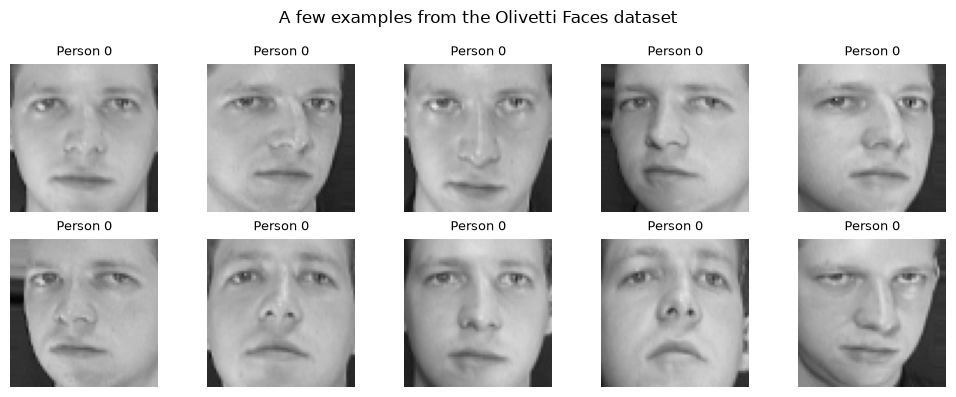

In [2]:
faces = fetch_olivetti_faces(shuffle=False)
X = faces.data
y = faces.target

print("Images and features:", X.shape)
print("Labels:", y.shape)
print("Number of people:", len(np.unique(y)))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.flat, faces.images[:10], y[:10]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Person {label}", fontsize=9)
    ax.axis("off")
plt.suptitle("A few examples from the Olivetti Faces dataset")
plt.tight_layout()
plt.savefig(RESULT_DIR / "dataset_examples.png", dpi=200)
plt.show()

## 3. Make one fixed split

For each of the 40 people, I shuffle their 10 image indices, then assign 6 to training, 2 to validation, and 2 to testing. I save the indices and will reuse them in Q2 and Q3.

In [3]:
train_idx, val_idx, test_idx = [], [], []
for person in np.unique(y):
    indices = np.where(y == person)[0]
    shuffled = rng.permutation(indices)
    train_idx.extend(shuffled[:6])
    val_idx.extend(shuffled[6:8])
    test_idx.extend(shuffled[8:10])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

assert (len(train_idx), len(val_idx), len(test_idx)) == (240, 80, 80)
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == 400
for person in np.unique(y):
    assert (np.sum(y_train == person), np.sum(y_val == person), np.sum(y_test == person)) == (6, 2, 2)

np.savez(DATA_DIR / "saved_split.npz", train_idx=train_idx, val_idx=val_idx,
         test_idx=test_idx, seed=SEED)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Saved data/saved_split.npz")

Training: (240, 4096)
Validation: (80, 4096)
Testing: (80, 4096)
Saved data/saved_split.npz


## Q1(a) — Single-tree baseline

In [5]:
depths = [2, 4, 8, 16, None]
leaf_sizes = [1, 2, 4]
rows = []
tree_models = {}

for depth in depths:
    for leaf_size in leaf_sizes:
        tree = DecisionTreeClassifier(max_depth=depth,
                                      min_samples_leaf=leaf_size,
                                      random_state=SEED)
        tree.fit(X_train, y_train)

        _, occupancy = np.unique(tree.apply(X_train), return_counts=True)
        rows.append({
            "depth": depth,
            "min_leaf": leaf_size,
            "train_acc": tree.score(X_train, y_train),
            "val_acc": tree.score(X_val, y_val),
            "n_leaves": tree.get_n_leaves(),
            "mean_occupancy": occupancy.mean(),
            "singleton_fraction": np.mean(occupancy == 1)
        })
        tree_models[(depth, leaf_size)] = tree

single_results = pd.DataFrame(rows)
assert len(single_results) == 15
single_results.to_csv(RESULT_DIR / "q1a_tree_configs.csv", index=False)
display(single_results.round(4))

,depth,min_leaf,train_acc,val_acc,n_leaves,mean_occupancy,singleton_fraction
0,2.0,1,0.0750,0.0625,3,80.0000,0.0000
1,2.0,2,0.0750,0.0625,3,80.0000,0.0000
2,2.0,4,0.0750,0.0625,3,80.0000,0.0000
3,4.0,1,0.1250,0.0875,5,48.0000,0.0000
4,4.0,2,0.1250,0.0875,5,48.0000,0.0000
5,4.0,4,0.1250,0.0875,5,48.0000,0.0000
6,8.0,1,0.2250,0.1750,9,26.6667,0.0000
7,8.0,2,0.2250,0.1750,9,26.6667,0.0000
8,8.0,4,0.2250,0.1750,9,26.6667,0.0000
9,16.0,1,0.4458,0.3250,18,13.3333,0.0000


In [6]:
ranked_trees = single_results.sort_values(
    ["val_acc", "n_leaves", "min_leaf"], ascending=[False, True, False]
)
chosen = ranked_trees.iloc[0]
best_depth = None if pd.isna(chosen["depth"]) else int(chosen["depth"])
best_leaf = int(chosen["min_leaf"])
best_tree = tree_models[(best_depth, best_leaf)]

single_results["test_acc"] = [
    tree_models[(depth, leaf_size)].score(X_test, y_test)
    for depth in depths for leaf_size in leaf_sizes
]
single_results.to_csv(RESULT_DIR / "q1a_tree_configs.csv", index=False)
print("Selected max_depth:", best_depth)
print("Selected min_samples_leaf:", best_leaf)
print("Training accuracy:", round(best_tree.score(X_train, y_train), 4))
print("Validation accuracy:", round(best_tree.score(X_val, y_val), 4))
print("Clean test accuracy:", round(best_tree.score(X_test, y_test), 4))

Selected max_depth: None
Selected min_samples_leaf: 4
Training accuracy: 0.9833
Validation accuracy: 0.6
Clean test accuracy: 0.5375


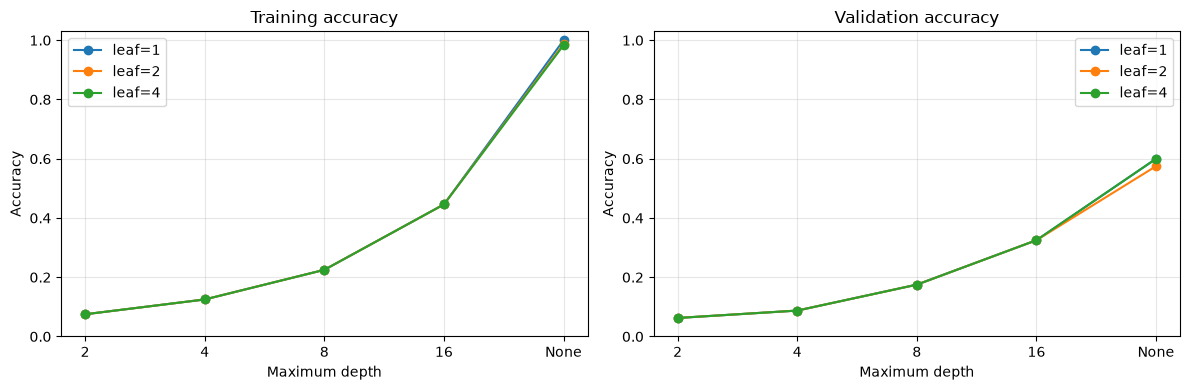

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for leaf_size in leaf_sizes:
    subset = single_results[single_results["min_leaf"] == leaf_size]
    positions = np.arange(len(subset))
    axes[0].plot(positions, subset["train_acc"], marker="o", label=f"leaf={leaf_size}")
    axes[1].plot(positions, subset["val_acc"], marker="o", label=f"leaf={leaf_size}")
for ax, title in zip(axes, ["Training accuracy", "Validation accuracy"]):
    ax.set_xticks(range(5), ["2", "4", "8", "16", "None"])
    ax.set_xlabel("Maximum depth")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.03)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / "q1a_accuracy_by_depth.png", dpi=200)
plt.show()

## Q1(b) Bootstrap bagging from scratch

In [8]:
ensemble_sizes = [1, 5, 10, 25, 50, 100, 200]
n_train = len(y_train)
bootstrap_rng = np.random.default_rng(SEED + 1)
bootstrap_indices = [bootstrap_rng.integers(0, n_train, size=n_train)
                     for _ in range(max(ensemble_sizes))]
tree_seeds = np.random.default_rng(SEED + 2).integers(
    0, 2**31 - 1, size=max(ensemble_sizes))

def fit_bootstrap_tree(i):
    sampled = bootstrap_indices[i]
    tree = DecisionTreeClassifier(max_depth=best_depth,
                                  min_samples_leaf=best_leaf,
                                  random_state=int(tree_seeds[i]))
    tree.fit(X_train[sampled], y_train[sampled])
    return tree

start = time.perf_counter()
bag_trees = Parallel(n_jobs=N_JOBS, backend="threading", verbose=5)(
    delayed(fit_bootstrap_tree)(i) for i in range(max(ensemble_sizes))
)
bag_train_time = time.perf_counter() - start

print("Trained", len(bag_trees), "bootstrap trees")
print(f"Total training time: {bag_train_time:.2f} seconds")

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    5.5s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   31.6s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  1.2min


Trained 200 bootstrap trees
Total training time: 95.34 seconds


[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:  1.6min finished


### Voting helper

For each image, I count votes for all 40 people and select the class with the most votes. `argmax` resolves ties consistently using the smallest class index.

In [9]:
K = len(np.unique(y))

def vote_counts(trees, X_input):
    counts = np.zeros((len(X_input), K), dtype=int)
    for tree in trees:
        predicted = tree.predict(X_input).astype(int)
        counts[np.arange(len(X_input)), predicted] += 1
    return counts

def bag_predict(trees, X_input):
    return vote_counts(trees, X_input).argmax(axis=1)

expected_unique = n_train * (1 - (1 - 1/n_train)**n_train)
actual_unique = [len(np.unique(sample)) for sample in bootstrap_indices]
print(f"Expected unique images in one bootstrap sample: {expected_unique:.2f}")
print(f"Measured mean across 200 samples: {np.mean(actual_unique):.2f}")

Expected unique images in one bootstrap sample: 151.89
Measured mean across 200 samples: 151.63


In [10]:
bag_rows = []
for B in ensemble_sizes:
    trees = bag_trees[:B]
    bag_rows.append({
        "B": B,
        "train_acc": accuracy_score(y_train, bag_predict(trees, X_train)),
        "val_acc": accuracy_score(y_val, bag_predict(trees, X_val)),
        "test_acc": accuracy_score(y_test, bag_predict(trees, X_test)),
        "avg_distinct_bootstrap": np.mean(actual_unique[:B])
    })
bag_results = pd.DataFrame(bag_rows)
bag_results.to_csv(RESULT_DIR / "q1b_bagging_accuracy.csv", index=False)
display(bag_results.round(4))

,B,train_acc,val_acc,test_acc,avg_distinct_bootstrap
0,1,0.6792,0.3375,0.3500,157.00
1,5,0.9167,0.5625,0.5750,152.60
2,10,0.9875,0.7250,0.6750,152.20
3,25,1.0000,0.9250,0.7500,151.92
4,50,0.9958,0.9375,0.8000,151.46
5,100,0.9958,0.9250,0.7875,151.85
6,200,1.0000,0.9250,0.8250,151.63


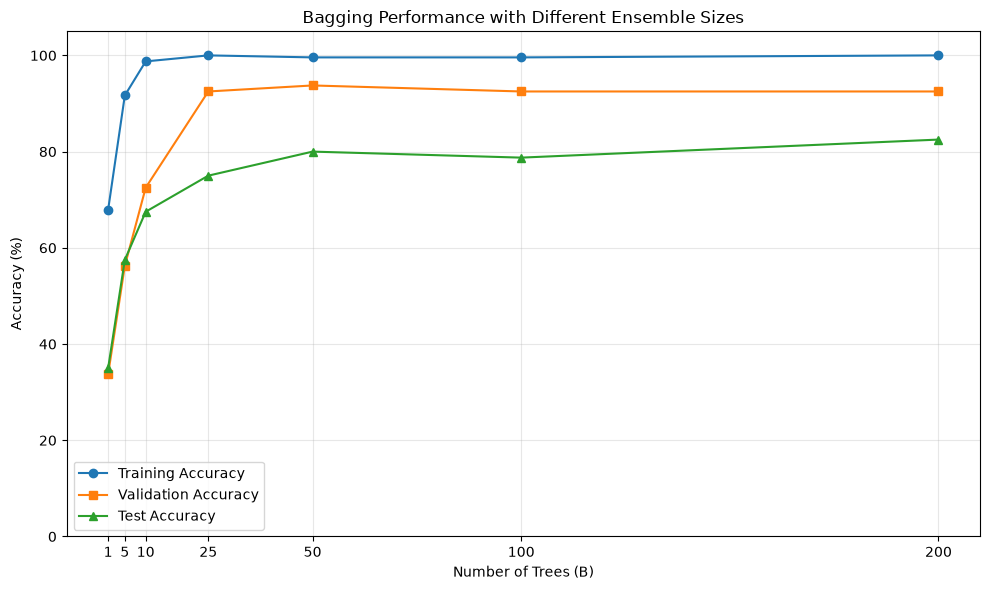

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(bag_results["B"], bag_results["train_acc"] * 100,
         marker="o", label="Training Accuracy")

plt.plot(bag_results["B"], bag_results["val_acc"] * 100,
         marker="s", label="Validation Accuracy")

plt.plot(bag_results["B"], bag_results["test_acc"] * 100,
         marker="^", label="Test Accuracy")

plt.xlabel("Number of Trees (B)")
plt.ylabel("Accuracy (%)")
plt.title("Bagging Performance with Different Ensemble Sizes")

plt.xticks(bag_results["B"])
plt.ylim(0, 105)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULT_DIR / "q1b_bagging_accuracy.png", dpi=300)
plt.show()

## Q1(c) Out of bag accuracy, disagreement and vote margins

In [11]:
train_preds = np.stack([tree.predict(X_train).astype(int) for tree in bag_trees])
val_preds = np.stack([tree.predict(X_val).astype(int) for tree in bag_trees])
oob_mask = np.stack([
    ~np.isin(np.arange(n_train), bootstrap_indices[i])
    for i in range(len(bag_trees))
])

def oob_accuracy(B):
    counts = np.zeros((n_train, K), dtype=int)
    available = np.zeros(n_train, dtype=int)
    for i in range(B):
        indices = np.where(oob_mask[i])[0]
        counts[indices, train_preds[i, indices]] += 1
        available[indices] += 1
    covered = available > 0
    if not np.any(covered):
        return np.nan, 0
    return accuracy_score(y_train[covered], counts[covered].argmax(axis=1)), int(covered.sum())

def pair_disagreement(B):
    if B < 2:
        return np.nan
    values = [np.mean(val_preds[a] != val_preds[b])
              for a, b in combinations(range(B), 2)]
    return float(np.mean(values))

def average_vote_margin(B):
    counts = vote_counts(bag_trees[:B], X_val)
    top_two = np.sort(counts, axis=1)[:, -2:]
    return float(np.mean((top_two[:, 1] - top_two[:, 0]) / B))

analysis_rows = []
for B in ensemble_sizes:
    oob_acc, n_covered = oob_accuracy(B)
    analysis_rows.append({
        "B": B,
        "oob_accuracy": oob_acc,
        "oob_covered": n_covered,
        "pair_disagreement": pair_disagreement(B),
        "vote_margin": average_vote_margin(B)
    })
analysis_df = pd.DataFrame(analysis_rows)
analysis_df.to_csv(RESULT_DIR / "q1c_ensemble_analysis.csv", index=False)
display(analysis_df.round(4))

,B,oob_accuracy,oob_covered,pair_disagreement,vote_margin
0,1,0.2651,83,NaN,1.0000
1,5,0.2570,214,0.8400,0.2125
2,10,0.3263,236,0.8053,0.2338
3,25,0.5542,240,0.8124,0.2335
4,50,0.6542,240,0.8098,0.2485
5,100,0.7458,240,0.8087,0.2529
6,200,0.7458,240,0.8080,0.2549


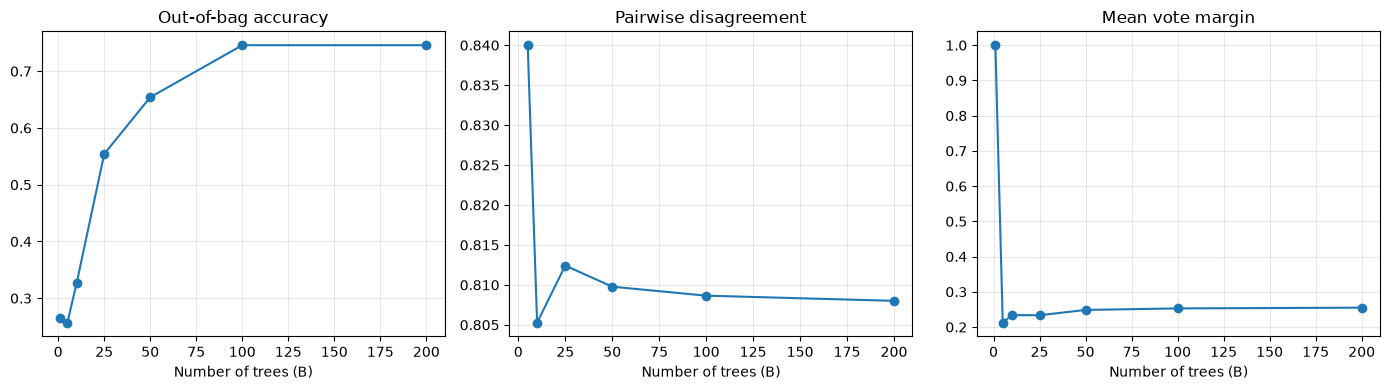

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(analysis_df.B, analysis_df.oob_accuracy, marker="o")
axes[0].set_title("Out-of-bag accuracy")
axes[1].plot(analysis_df.B, analysis_df.pair_disagreement, marker="o")
axes[1].set_title("Pairwise disagreement")
axes[2].plot(analysis_df.B, analysis_df.vote_margin, marker="o")
axes[2].set_title("Mean vote margin")
for ax in axes:
    ax.set_xlabel("Number of trees (B)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "q1c_ensemble_metrics.png", dpi=200)
plt.show()

In [14]:
chosen_bag_row = bag_results.sort_values(["val_acc", "B"], ascending=[False, True]).iloc[0]
BEST_B = int(chosen_bag_row.B)
final_bag = bag_trees[:BEST_B]
print("Selected ensemble size:", BEST_B)
print("Validation accuracy:", round(chosen_bag_row.val_acc, 4))
print("Clean test accuracy:", round(chosen_bag_row.test_acc, 4))

Selected ensemble size: 50
Validation accuracy: 0.9375
Clean test accuracy: 0.8


## Q1(d) Missing central region

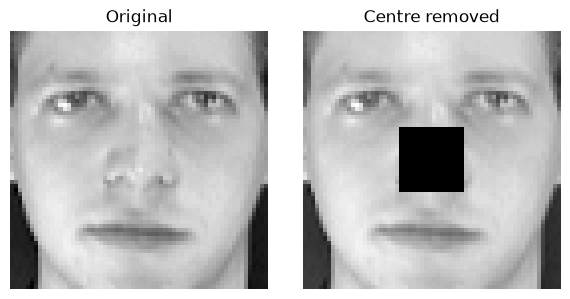

In [15]:
def mask_centre(X_input):
    images = X_input.reshape(-1, 64, 64).copy()
    images[:, 24:40, 24:40] = 0
    return images.reshape(-1, 4096)

X_test_masked = mask_centre(X_test)
np.save(DATA_DIR / "X_test_masked.npy", X_test_masked)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(X_test[0].reshape(64, 64), cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(X_test_masked[0].reshape(64, 64), cmap="gray")
axes[1].set_title("Centre removed")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(RESULT_DIR / "q1d_mask_example.png", dpi=200)
plt.show()

In [16]:
tree_clean = best_tree.predict(X_test)
tree_masked = best_tree.predict(X_test_masked)
bag_clean = bag_predict(final_bag, X_test)
bag_masked = bag_predict(final_bag, X_test_masked)

comparison = pd.DataFrame([
    {"model": "Single tree", "clean_test_acc": accuracy_score(y_test, tree_clean),
     "masked_test_acc": accuracy_score(y_test, tree_masked)},
    {"model": f"Bagging (B={BEST_B})", "clean_test_acc": accuracy_score(y_test, bag_clean),
     "masked_test_acc": accuracy_score(y_test, bag_masked)}
])
comparison["accuracy_drop"] = comparison.clean_test_acc - comparison.masked_test_acc
comparison.to_csv(RESULT_DIR / "q1d_clean_masked_comparison.csv", index=False)
display(comparison.round(4))

,model,clean_test_acc,masked_test_acc,accuracy_drop
0,Single tree,0.5375,0.3500,0.1875
1,Bagging (B=50),0.8000,0.6125,0.1875


### Two examples where bagging fixes the single tree's mistake

Test image 0 | True class: 0
Single tree predicted: 9
Bagging predicted: 0
Bagging votes: {0: 26, 1: 3, 3: 1, 4: 1, 6: 1, 7: 10, 9: 2, 12: 1, 13: 1, 15: 1, 16: 1, 17: 1, 19: 1}


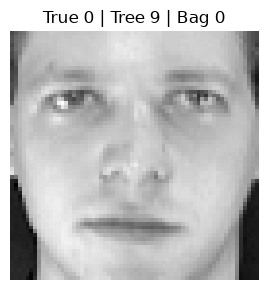

Test image 1 | True class: 0
Single tree predicted: 12
Bagging predicted: 0
Bagging votes: {0: 16, 1: 2, 2: 4, 3: 1, 5: 1, 11: 1, 12: 2, 13: 1, 14: 1, 15: 1, 16: 11, 17: 4, 22: 1, 27: 1, 35: 1, 39: 2}


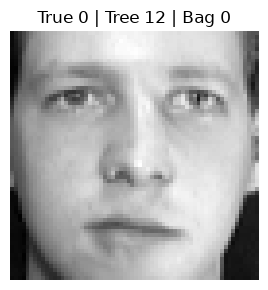

In [17]:
fixed_cases = np.where((tree_clean != y_test) & (bag_clean == y_test))[0]
if len(fixed_cases) < 2:
    print(f"Only {len(fixed_cases)} correction(s) found on the clean test set.")
    print("Do not invent additional cases. Inspect masked results as well if needed.")

for idx in fixed_cases[:2]:
    counts = vote_counts(final_bag, X_test[idx:idx+1])[0]
    votes = {int(cls): int(num) for cls, num in enumerate(counts) if num > 0}
    print(f"Test image {idx} | True class: {y_test[idx]}")
    print(f"Single tree predicted: {tree_clean[idx]}")
    print(f"Bagging predicted: {bag_clean[idx]}")
    print("Bagging votes:", votes)
    plt.figure(figsize=(3, 3))
    plt.imshow(X_test[idx].reshape(64, 64), cmap="gray")
    plt.title(f"True {y_test[idx]} | Tree {tree_clean[idx]} | Bag {bag_clean[idx]}")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(RESULT_DIR / f"q1d_fixed_case_{idx}.png", dpi=200)
    plt.show()

In [18]:
def average_confidence(model, images, is_bagging=False):

    if is_bagging:
        votes = vote_counts(model, images)
        confidence = votes.max(axis=1) / len(model)
    else:
        confidence = model.predict_proba(images).max(axis=1)

    return confidence.mean()


confidence_results = pd.DataFrame({
    "Model": ["Single Tree", "Bagging"],
    "Clean Confidence": [
        average_confidence(best_tree, X_test),
        average_confidence(final_bag, X_test, True)
    ],
    "Masked Confidence": [
        average_confidence(best_tree, X_test_masked),
        average_confidence(final_bag, X_test_masked, True)
    ]
})

display(confidence_results.round(4))

,Model,Clean Confidence,Masked Confidence
0,Single Tree,0.9670,0.9982
1,Bagging,0.3672,0.2660


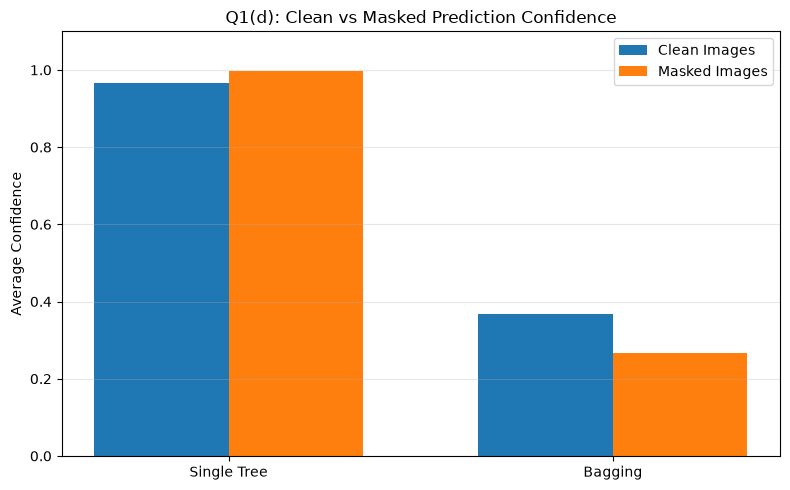

In [21]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Single Tree", "Bagging"]

clean = [0.9670, 0.3672]
masked = [0.9982, 0.2660]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, clean, width, label="Clean Images")
plt.bar(x + width/2, masked, width, label="Masked Images")

plt.xticks(x, models)
plt.ylabel("Average Confidence")
plt.title("Q1(d): Clean vs Masked Prediction Confidence")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(RESULT_DIR / "q1d_confidence_comparison.png", dpi=300)
plt.show()